In [ ]:
import pandas as pd

# Define URLs for three months with existing data (e.g., May 2024 to July 2024)
urls = [
    'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-05.parquet',
    'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-06.parquet',
    'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-07.parquet'
]

# Load and combine datasets into a single DataFrame
dfs = [pd.read_parquet(url) for url in urls]
df = pd.concat(dfs, ignore_index=True)

print("Data loaded successfully!")
print(f"Total rows loaded: {len(df):,}")

Data loaded successfully!
Total rows loaded: 10,339,929


In [ ]:
import pandas as pd
import gc

# Drop the old dataset and free up memory
try:
    del df, dfs, urls
    gc.collect()
    print("Previous dataset dropped and memory cleared.")
except NameError:
    print("No existing variables to clear.")

# Define URLs for the last 3 months of 2026 data
urls = [
    'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-05.parquet',
    'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-06.parquet',
    'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-07.parquet'
]

print("Loading the 2026 dataset...")
dfs = [pd.read_parquet(url) for url in urls]
df = pd.concat(dfs, ignore_index=True)

print("New dataset loaded successfully!")
print(f"Total rows loaded: {len(df):,}")

Previous dataset dropped and memory cleared.
Loading the 2026 dataset...
New dataset loaded successfully!
Total rows loaded: 11,458,193


In [ ]:
# List all column names
print("Column Names:")
print(df.columns.tolist())

# View detailed schema (Data types + memory usage)
df.info()

Column Names:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'request_source']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11458193 entries, 0 to 11458192
Data columns (total 21 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int

In [ ]:
# Define your exact start and end bounds
start_date = '2026-05-01'
end_date = '2026-07-31'

df = df[(df['tpep_pickup_datetime'] >= start_date) & (df['tpep_pickup_datetime'] <= end_date)].copy()

In [ ]:
# Record original dataset size
initial_count = len(df)

# Filter invalid trip records
df_clean = df[
    (df['trip_distance'] > 0) &                            # Distance must be positive
    (df['passenger_count'] > 0) &                          # At least 1 passenger
    (df['tpep_dropoff_datetime'].notna()) &               # Dropoff timestamp present
    (df['tpep_dropoff_datetime'] > df['tpep_pickup_datetime']) # Dropoff occurs after pickup
].copy()

print(f"Removed {initial_count - len(df_clean):,} invalid records.")

Removed 3,183,668 invalid records.


In [ ]:
# Keep only records where pickup and dropoff locations are valid NYC Taxi Zones (1–263)
df_clean = df_clean[
    df_clean['PULocationID'].between(1, 263) &
    df_clean['DOLocationID'].between(1, 263)
].copy()

print(f"Remaining rows after filtering location outliers: {len(df_clean):,}")

Remaining rows after filtering location outliers: 8,093,585


In [ ]:
# # Convert pickup column to datetime if not already
# df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])

# # Extract date and hour attributes
# df['pickup_date'] = df['tpep_pickup_datetime'].dt.date
# df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour

# # Aggregate hourly trip details
# hourly_summary = df.groupby(['pickup_date', 'pickup_hour']).agg(
#     total_trips=('VendorID', 'count'),
#     avg_fare=('fare_amount', 'mean'),
#     avg_distance=('trip_distance', 'mean'),
#     total_revenue=('total_amount', 'sum')
# ).reset_index()

# # View hourly breakdown
# hourly_summary.head(10)

In [ ]:
# len(hourly_summary)

In [ ]:
# hourly_summary.tail(10)

In [ ]:
# Ensure datetime columns are properly formatted
df_clean['tpep_pickup_datetime'] = pd.to_datetime(df_clean['tpep_pickup_datetime'])
df_clean['tpep_dropoff_datetime'] = pd.to_datetime(df_clean['tpep_dropoff_datetime'])

# -------------------------------------------------------------
# 1. Extract Time Attributes
# -------------------------------------------------------------

# Hour of day (0-23)
df_clean['pickup_hour'] = df_clean['tpep_pickup_datetime'].dt.hour

# Day of week name (e.g., 'Monday', 'Tuesday')
df_clean['pickup_day_of_week'] = df_clean['tpep_pickup_datetime'].dt.day_name()

# Boolean flag for weekends (5 = Saturday, 6 = Sunday)
df_clean['is_weekend'] = df_clean['tpep_pickup_datetime'].dt.dayofweek.isin([5, 6])

# Trip duration in minutes
df_clean['trip_duration_minutes'] = (
    df_clean['tpep_dropoff_datetime'] - df_clean['tpep_pickup_datetime']
).dt.total_seconds() / 60.0

# Filter out zero or negative duration records to avoid division errors
df_clean = df_clean[df_clean['trip_duration_minutes'] > 0].copy()


# -------------------------------------------------------------
# 2. Calculate Derived Features
# -------------------------------------------------------------

# Average Speed (mph) = Distance (miles) / Time (hours)
df_clean['average_speed_mph'] = df_clean['trip_distance'] / (df_clean['trip_duration_minutes'] / 60.0)

# Tip Percentage = (tip_amount / fare_amount) * 100
# Handle division by zero when fare_amount <= 0 using np.where or safe division
import numpy as np

df_clean['tip_percentage'] = np.where(
    df_clean['fare_amount'] > 0,
    (df_clean['tip_amount'] / df_clean['fare_amount']) * 100,
    0.0
)

# Optional: Display a sample of the newly generated features
print("Feature engineering complete! Sample output:")
df_clean[['tpep_pickup_datetime', 'pickup_hour', 'pickup_day_of_week',
          'is_weekend', 'trip_duration_minutes', 'average_speed_mph', 'tip_percentage']].head()

Feature engineering complete! Sample output:


,tpep_pickup_datetime,pickup_hour,pickup_day_of_week,is_weekend,trip_duration_minutes,average_speed_mph,tip_percentage
0,2026-05-01 00:04:59,0,Friday,False,27.816667,16.198922,0.000000
1,2026-05-01 00:37:05,0,Friday,False,22.700000,16.229075,34.763636
2,2026-05-01 00:34:05,0,Friday,False,19.950000,7.218045,19.528796
5,2026-05-01 00:24:35,0,Friday,False,25.333333,13.950000,23.460208
6,2026-05-01 00:06:08,0,Friday,False,6.650000,14.436090,30.645161


/tmp/ipykernel_2460/3293598111.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


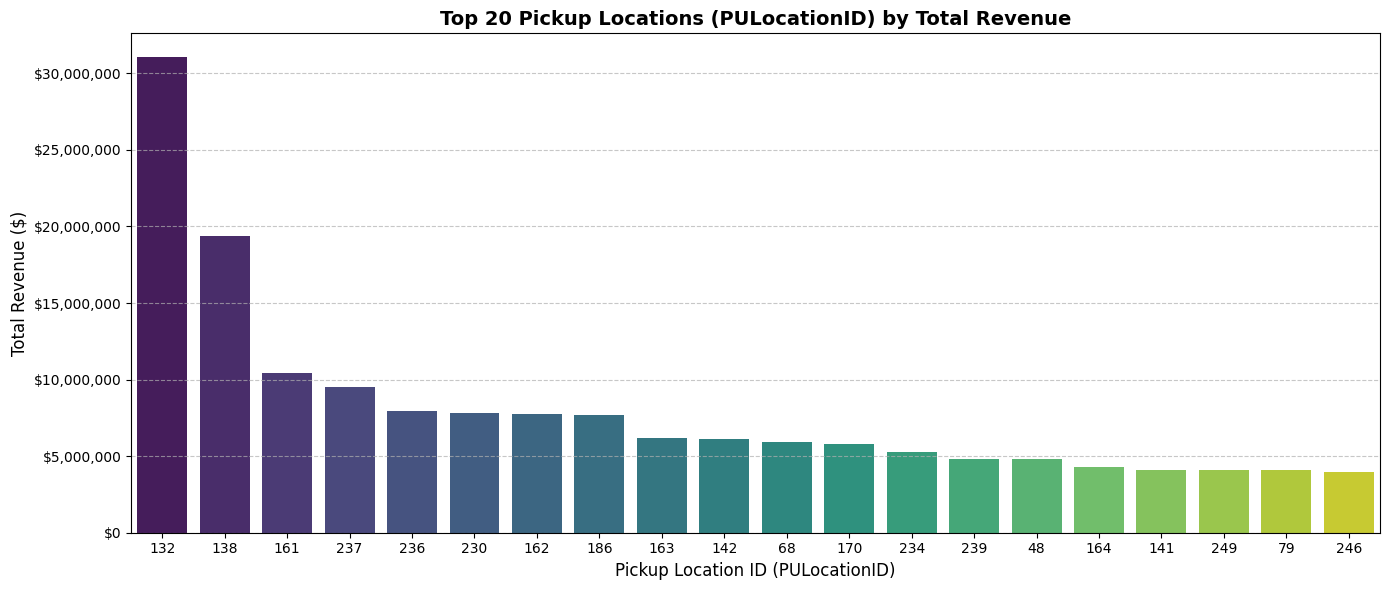

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aggregate total revenue (total_amount) by PULocationID
pu_revenue = (
    df_clean.groupby('PULocationID')['total_amount']
    .sum()
    .reset_index()
    .rename(columns={'total_amount': 'total_revenue'})
)

# 2. Sort by revenue and select top locations (e.g., Top 20)
top_pu_revenue = pu_revenue.sort_values(by='total_revenue', ascending=False).head(20)

# 3. Create the bar chart
plt.figure(figsize=(14, 6))
ax = sns.barplot(
    data=top_pu_revenue,
    x='PULocationID',
    y='total_revenue',
    order=top_pu_revenue['PULocationID'],
    palette='viridis'
)

# 4. Format labels and title
plt.title('Top 20 Pickup Locations (PULocationID) by Total Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Pickup Location ID (PULocationID)', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)

# Format y-axis values as currency ($M or $k)
ax.yaxis.set_major_formatter('${x:,.0f}')

# Rotate x-axis labels for clarity
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

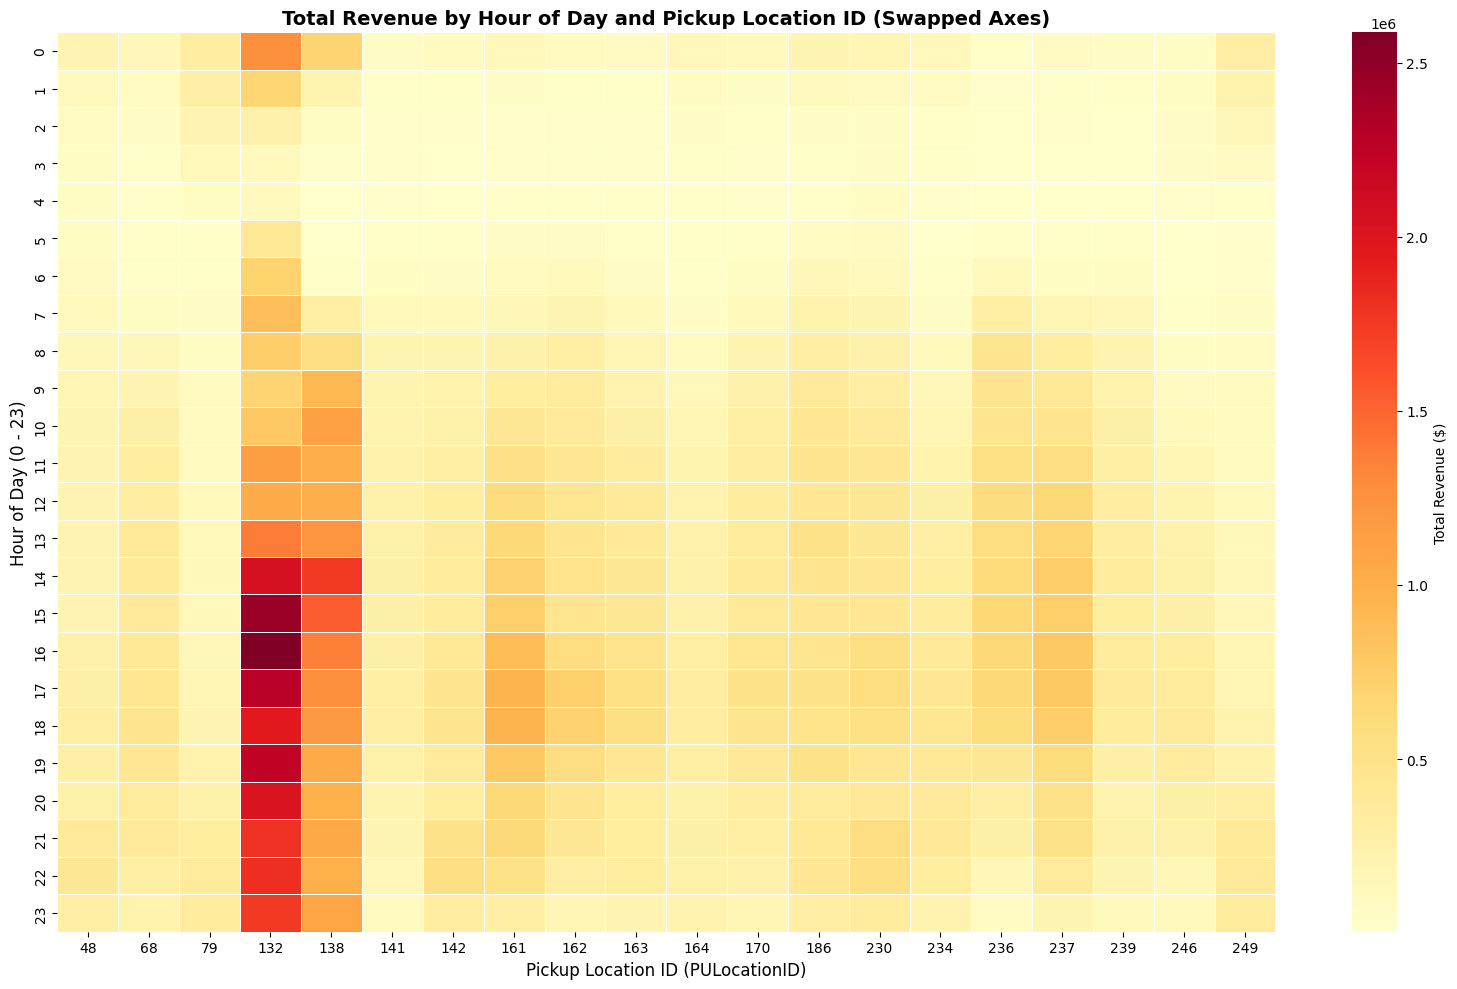

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identify the Top 20 PULocationIDs by total revenue
top_20_locations = (
    df_clean.groupby('PULocationID')['total_amount']
    .sum()
    .nlargest(20)
    .index
)

# 2. Filter dataset and aggregate
heatmap_data = (
    df_clean[df_clean['PULocationID'].isin(top_20_locations)]
    .groupby(['PULocationID', 'pickup_hour'])['total_amount']
    .sum()
    .unstack(level='pickup_hour', fill_value=0)
)

# 3. Transpose the DataFrame (.T) to swap the X and Y axes
heatmap_data_transposed = heatmap_data.T

# 4. Create the Heatmap with swapped axes
plt.figure(figsize=(16, 10))
sns.heatmap(
    heatmap_data_transposed,
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Total Revenue ($)'}
)

plt.title('Total Revenue by Hour of Day and Pickup Location ID (Swapped Axes)', fontsize=14, fontweight='bold')
plt.xlabel('Pickup Location ID (PULocationID)', fontsize=12)
plt.ylabel('Hour of Day (0 - 23)', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# 1. Truncate pickup timestamp to the hour
df_clean['pickup_hour_dt'] = df_clean['tpep_pickup_datetime'].dt.floor('h')

# 2. Aggregate to create continuous hourly demand per location
hourly_demand = (
    df_clean.groupby(['PULocationID', 'pickup_hour_dt'])
    .size()
    .reset_index(name='trip_count')
)

# 3. Create a full grid (location x hour) so missing hours are explicitly filled with 0
locations = hourly_demand['PULocationID'].unique()
min_time = hourly_demand['pickup_hour_dt'].min()
max_time = hourly_demand['pickup_hour_dt'].max()

full_time_range = pd.date_range(start=min_time, end=max_time, freq='h')
full_grid = pd.MultiIndex.from_product(
    [locations, full_time_range],
    names=['PULocationID', 'pickup_hour_dt']
).to_frame().reset_index(drop=True)

df_grid = pd.merge(full_grid, hourly_demand, on=['PULocationID', 'pickup_hour_dt'], how='left')
df_grid['trip_count'] = df_grid['trip_count'].fillna(0)

# Sort strictly by location and time to calculate lags accurately
df_grid = df_grid.sort_values(['PULocationID', 'pickup_hour_dt']).reset_index(drop=True)

# 4. Extract Categorical & Time Features
df_grid['hour'] = df_grid['pickup_hour_dt'].dt.hour
df_grid['day_of_week'] = df_grid['pickup_hour_dt'].dt.dayofweek
df_grid['is_weekend'] = df_grid['day_of_week'].isin([5, 6]).astype(int)
df_grid['month'] = df_grid['pickup_hour_dt'].dt.month

# 5. Extract Lag Features per PULocationID
grouped = df_grid.groupby('PULocationID')['trip_count']

df_grid['lag_1h'] = grouped.shift(1)
df_grid['lag_24h'] = grouped.shift(24)         # Demand 1 day ago
df_grid['lag_168h'] = grouped.shift(168)       # Demand 1 week ago

# 6. Extract Rolling / Cumulative Features
df_grid['rolling_mean_24h'] = grouped.transform(lambda x: x.shift(1).rolling(window=24).mean())
df_grid['rolling_std_24h']  = grouped.transform(lambda x: x.shift(1).rolling(window=24).std())
df_grid['rolling_mean_7d']  = grouped.transform(lambda x: x.shift(1).rolling(window=168).mean())

# 7. Drop NaN rows created by the 1-week lag (168 hours)
df_model = df_grid.dropna().reset_index(drop=True)

print("Feature dataset created successfully!")
print(f"Total records ready for modeling: {len(df_model):,}")
df_model.head()

Feature dataset created successfully!
Total records ready for modeling: 522,403


,PULocationID,pickup_hour_dt,trip_count,hour,day_of_week,is_weekend,month,lag_1h,lag_24h,lag_168h,rolling_mean_24h,rolling_std_24h,rolling_mean_7d
0,1,2026-05-08 00:00:00,0.0,0,4,0,5,0.0,0.0,0.0,0.25,0.53161,0.154762
1,1,2026-05-08 01:00:00,0.0,1,4,0,5,0.0,0.0,0.0,0.25,0.53161,0.154762
2,1,2026-05-08 02:00:00,0.0,2,4,0,5,0.0,0.0,0.0,0.25,0.53161,0.154762
3,1,2026-05-08 03:00:00,0.0,3,4,0,5,0.0,0.0,0.0,0.25,0.53161,0.154762
4,1,2026-05-08 04:00:00,0.0,4,4,0,5,0.0,0.0,0.0,0.25,0.53161,0.154762


In [ ]:
# 1. Identify the maximum timestamp in the dataset
max_date = df_model['pickup_hour_dt'].max()

# 2. Define cutoff points for Test and Validation sets
# Test set: Last 7 days (168 hours)
test_cutoff = max_date - pd.Timedelta(days=7)

# Validation set: The 7 days prior to the test set
val_cutoff = test_cutoff - pd.Timedelta(days=7)

# 3. Perform Chronological Split
train_df = df_model[df_model['pickup_hour_dt'] < val_cutoff].copy()
val_df   = df_model[(df_model['pickup_hour_dt'] >= val_cutoff) & (df_model['pickup_hour_dt'] < test_cutoff)].copy()
test_df  = df_model[df_model['pickup_hour_dt'] >= test_cutoff].copy()

# Print dataset split summary
print(f"Train Set      : {train_df['pickup_hour_dt'].min()} to {train_df['pickup_hour_dt'].max()} ({len(train_df):,} rows)")
print(f"Validation Set : {val_df['pickup_hour_dt'].min()} to {val_df['pickup_hour_dt'].max()} ({len(val_df):,} rows)")
print(f"Test Set       : {test_df['pickup_hour_dt'].min()} to {test_df['pickup_hour_dt'].max()} ({len(test_df):,} rows)")

# 4. Define Feature Columns and Target Variable
feature_cols = [
    'PULocationID', 'hour', 'day_of_week', 'is_weekend', 'month',
    'lag_1h', 'lag_24h', 'lag_168h',
    'rolling_mean_24h', 'rolling_std_24h', 'rolling_mean_7d'
]
target_col = 'trip_count'

# Separate features (X) and target labels (y)
X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val, y_val     = val_df[feature_cols], val_df[target_col]
X_test, y_test   = test_df[feature_cols], test_df[target_col]

print("\nFeatures and Target variables defined successfully!")

Train Set      : 2026-05-08 00:00:00 to 2026-07-16 23:00:00 (435,120 rows)
Validation Set : 2026-07-17 00:00:00 to 2026-07-23 23:00:00 (43,512 rows)
Test Set       : 2026-07-24 00:00:00 to 2026-07-31 00:00:00 (43,771 rows)

Features and Target variables defined successfully!


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, median_absolute_error, r2_score
import xgboost as xgb
import lightgbm as lgb

# Define Evaluation Metric Function
def evaluate_forecast(y_true, y_pred, model_name="Model"):
    # Clip predictions at 0 (demand cannot be negative)
    y_pred = np.clip(y_pred, 0, None)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mdae = median_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        'Model': model_name,
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4),
        'MdAE': round(mdae, 4),
        'R2': round(r2, 4)
    }

results = []

# -------------------------------------------------------------
# 1. Linear Regression Baseline
# -------------------------------------------------------------
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
results.append(evaluate_forecast(y_test, lr_preds, "Linear Regression"))

# -------------------------------------------------------------
# 2. XGBoost Regressor
# -------------------------------------------------------------
xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)
xgb_preds = xgb_model.predict(X_test)
results.append(evaluate_forecast(y_test, xgb_preds, "XGBoost"))

# -------------------------------------------------------------
# 3. LightGBM Regressor
# -------------------------------------------------------------
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(50, verbose=False)]
)
lgb_preds = lgb_model.predict(X_test)
results.append(evaluate_forecast(y_test, lgb_preds, "LightGBM"))

# -------------------------------------------------------------
# Comparison Table
# -------------------------------------------------------------
results_df = pd.DataFrame(results)
print("--- Model Performance Comparison on Test Set ---")
print(results_df.to_string(index=False))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.042445 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1817
[LightGBM] [Info] Number of data points in the train set: 435120, number of used features: 11
[LightGBM] [Info] Start training from score 14.353498
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

# -------------------------------------------------------------
# 1. Apply Advanced Preprocessing
# -------------------------------------------------------------

df_cv = df_model.copy()

# A. Cyclical Encoding for Hour and Day
df_cv['hour_sin'] = np.sin(2 * np.pi * df_cv['hour'] / 24.0)
df_cv['hour_cos'] = np.cos(2 * np.pi * df_cv['hour'] / 24.0)
df_cv['day_sin']  = np.sin(2 * np.pi * df_cv['day_of_week'] / 7.0)
df_cv['day_cos']  = np.cos(2 * np.pi * df_cv['day_of_week'] / 7.0)

# B. Convert PULocationID to categorical dtype for LightGBM/XGBoost
df_cv['PULocationID'] = df_cv['PULocationID'].astype('category')

# Define updated feature set
features = [
    'PULocationID', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
    'is_weekend', 'month', 'lag_1h', 'lag_24h', 'lag_168h',
    'rolling_mean_24h', 'rolling_std_24h', 'rolling_mean_7d'
]

# Ensure data is sorted chronologically
df_cv = df_cv.sort_values('pickup_hour_dt').reset_index(drop=True)

X = df_cv[features]
y = df_cv['trip_count']

# -------------------------------------------------------------
# 2. Setup TimeSeriesSplit Cross-Validation
# -------------------------------------------------------------

tscv = TimeSeriesSplit(n_splits=5)
lgb_cv_scores = []
xgb_cv_scores = []

print("Running 5-Fold Time-Series Cross Validation...\n")

fold = 1
for train_idx, val_idx in tscv.split(X):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    # Train LightGBM with Categorical Handling enabled
    model_lgb = lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    model_lgb.fit(X_tr, y_tr)
    preds_lgb = np.clip(model_lgb.predict(X_va), 0, None)
    mae_lgb = mean_absolute_error(y_va, preds_lgb)
    lgb_cv_scores.append(mae_lgb)

    # Train XGBoost with categorical support
    model_xgb = xgb.XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        enable_categorical=True,
        random_state=42,
        n_jobs=-1
    )
    model_xgb.fit(X_tr, y_tr)
    preds_xgb = np.clip(model_xgb.predict(X_va), 0, None)
    mae_xgb = mean_absolute_error(y_va, preds_xgb)
    xgb_cv_scores.append(mae_xgb)

    print(f"Fold {fold} | LightGBM MAE: {mae_lgb:.4f} | XGBoost MAE: {mae_xgb:.4f}")
    fold += 1

print("\n--- Final Cross-Validation Results ---")
print(f"LightGBM Mean CV MAE: {np.mean(lgb_cv_scores):.4f} (+/- {np.std(lgb_cv_scores):.4f})")
print(f"XGBoost  Mean CV MAE: {np.mean(xgb_cv_scores):.4f} (+/- {np.std(xgb_cv_scores):.4f})")

Running 5-Fold Time-Series Cross Validation...

Fold 1 | LightGBM MAE: 3.1746 | XGBoost MAE: 3.2221
Fold 2 | LightGBM MAE: 2.5561 | XGBoost MAE: 2.4984
Fold 3 | LightGBM MAE: 2.2365 | XGBoost MAE: 2.2405
Fold 4 | LightGBM MAE: 2.3757 | XGBoost MAE: 2.3552
Fold 5 | LightGBM MAE: 2.1728 | XGBoost MAE: 2.1695

--- Final Cross-Validation Results ---
LightGBM Mean CV MAE: 2.5031 (+/- 0.3606)
XGBoost  Mean CV MAE: 2.4971 (+/- 0.3792)


In [ ]:
import xgboost as xgb
import lightgbm as lgb

# Optimized Tuned LightGBM Regressor
tuned_lgb = lgb.LGBMRegressor(
    n_estimators=1000,          # Increased trees
    learning_rate=0.02,         # Slower, more precise learning rate
    max_depth=7,                # Slightly deeper to capture complex loops
    num_leaves=63,              # 2^(max_depth) - 1 guideline for leaf-wise growth
    subsample=0.8,              # Row subsampling to reduce overfitting
    colsample_bytree=0.8,       # Feature subsampling
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

# Optimized Tuned XGBoost Regressor
tuned_xgb = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.02,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    enable_categorical=True,
    random_state=42,
    n_jobs=-1
)

In [ ]:
from sklearn.metrics import r2_score

lgb_r2_scores = []
xgb_r2_scores = []

fold = 1
for train_idx, val_idx in tscv.split(X):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    # Train LightGBM
    model_lgb = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, random_state=42, n_jobs=-1, verbose=-1
    )
    model_lgb.fit(X_tr, y_tr)
    preds_lgb = np.clip(model_lgb.predict(X_va), 0, None)

    # Calculate R2 for this fold
    r2_lgb = r2_score(y_va, preds_lgb)
    lgb_r2_scores.append(r2_lgb)

    # Train XGBoost
    model_xgb = xgb.XGBRegressor(
        n_estimators=300, learning_rate=0.05, enable_categorical=True, random_state=42, n_jobs=-1
    )
    model_xgb.fit(X_tr, y_tr)
    preds_xgb = np.clip(model_xgb.predict(X_va), 0, None)

    r2_xgb = r2_score(y_va, preds_xgb)
    xgb_r2_scores.append(r2_xgb)

    print(f"Fold {fold} | LightGBM R2: {r2_lgb:.4f} | XGBoost R2: {r2_xgb:.4f}")
    fold += 1

print(f"\nMean LightGBM R2: {np.mean(lgb_r2_scores):.4f}")
print(f"Mean XGBoost R2:  {np.mean(xgb_r2_scores):.4f}")

Fold 1 | LightGBM R2: 0.9481 | XGBoost R2: 0.9443
Fold 2 | LightGBM R2: 0.9677 | XGBoost R2: 0.9671
Fold 3 | LightGBM R2: 0.9680 | XGBoost R2: 0.9667
Fold 4 | LightGBM R2: 0.9550 | XGBoost R2: 0.9544
Fold 5 | LightGBM R2: 0.9697 | XGBoost R2: 0.9689

Mean LightGBM R2: 0.9617
Mean XGBoost R2:  0.9603


In [ ]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score
import xgboost as xgb
import numpy as np

# 1. Define the hyperparameter grid to search over
param_grid = {
    'n_estimators': [300, 500],
    'max_depth': [4, 6],
    'learning_rate': [0.01, 0.05],
    'subsample': [0.8, 1.0]
}

# 2. Initialize the base XGBoost model
base_xgb = xgb.XGBRegressor(
    enable_categorical=True,
    random_state=42,
    n_jobs=-1
)

# 3. Setup Time-Series Cross-Validation to maintain chronological order
tscv = TimeSeriesSplit(n_splits=3)

# 4. Set up GridSearchCV using 'r2' as the scoring metric
grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    scoring='r2',
    cv=tscv,
    verbose=1,
    n_jobs=-1
)

# 5. Run the Grid Search on your training data
print("Running Grid Search for XGBoost...")
grid_search.fit(X_train, y_train)

# 6. Display the best parameters and best cross-validation R^2 score
print("\n--- Best Hyperparameters Found ---")
best_params = grid_search.best_params_
print(best_params)
print(f"Best CV R^2 Score: {grid_search.best_score_:.4f}")

# 7. Extract the best model and evaluate on the unseen Test Set
best_model = grid_search.best_estimator_
test_preds = best_model.predict(X_test)
test_preds = np.clip(test_preds, 0, None) # Ensure no negative trip predictions

final_test_r2 = r2_score(y_test, test_preds)
print(f"\nFinal Tuned Model Test Set R^2 Score: {final_test_r2:.4f}")

Running Grid Search for XGBoost...
Fitting 3 folds for each of 16 candidates, totalling 48 fits

--- Best Hyperparameters Found ---
{'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300, 'subsample': 1.0}
Best CV R^2 Score: 0.9413

Final Tuned Model Test Set R^2 Score: 0.9643
